# Week 7 · Visualising environmental data: charts, maps and satellite images

**CMT124** · Thursday 19 November 2026

Last week you turned tables into GeoDataFrames, joined renewable energy projects to districts, and met rasters on a tiny grid of 48 pixels. Today you make all of that **visible**: charts that answer a question, maps you can zoom into, and real satellite images from Google Earth Engine.

By the end of today you can choose a chart for a question and build it with Matplotlib and seaborn; make a fair choropleth and an interactive Folium map; and put a Sentinel-2 image and an NDVI layer from Earth Engine on the same kind of map.

Today has three teaching parts and a guided lab: **Hour 1** charts that answer a question · **Hour 2** from static to interactive maps · **Hour 3** satellite rasters with Earth Engine · **Guided lab** Wales from a map and from space.

## Setup

Run this cell first. It loads the libraries and `get_data()`, which finds the course datasets. pandas, GeoPandas, Matplotlib, seaborn and Folium are already installed in Colab. Earth Engine gets its own setup cell in Hour 3.

In [ ]:
# --- Setup: run this cell first -------------------------------------------------
# Course datasets live in the course repository under 2026-27/datasets/.
# get_data() uses a local copy if the notebook runs inside a copy of the repository;
# otherwise (e.g. in Google Colab) it downloads the file once and reuses it.
import os
import urllib.request

COURSE_REPO = "OWNER/REPO"
BASE_URL = f"https://raw.githubusercontent.com/{COURSE_REPO}/main/2026-27/"


def course_file(relpath):
    """Return a local path to a course file such as 'datasets/owid_co2_cleaned.csv'."""
    for root in ("../../..", "."):                     # 1) running inside a copy of the repository
        path = os.path.join(root, relpath)
        if os.path.exists(path):
            return path
    path = os.path.join("course_files", relpath)       # 2) Colab: download once
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        urllib.request.urlretrieve(BASE_URL + relpath, path)
    return path


def get_data(name):
    """Return a local path to a course dataset, e.g. get_data('owid_co2_cleaned.csv')."""
    return course_file("datasets/" + name)

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

## Hour 1 · Charts that answer a question

### Two reasons to draw a chart

| | **Exploring** (the chart is for you) | **Communicating** (the chart is for a reader) |
|---|---|---|
| Question | What does the data look like? Is anything wrong or missing? | What did I find? |
| Polish | quick and rough is fine | labels, units, a title that states the point |

You explore **before** you analyse, to catch problems, and you communicate **after**, to show what you found. Today's charts are communication charts: each one should answer a question at a glance.

### Which chart? Start from the question

| What would you like to show? | Start with |
|---|---|
| **Change over time** | line chart |
| **Distribution** of one variable | histogram |
| **Comparison** of groups | bar chart (one number per group) or boxplot (a whole distribution per group) |
| **Relationship** between two variables | scatter plot |

This hour uses three of them on the CO₂ table from Week 6: **lines** for change over time, a **histogram** for one distribution, and **boxplots** to compare distributions.

### What not to do

* **Hard comparisons.** Keep what you compare on the same scale, and never put two units (tonnes and °C) on one axis.
* **Neglecting the origin.** A bar's length is its value. If the axis doesn't start at zero, a 40 / 60 split can look like 1 to 10:

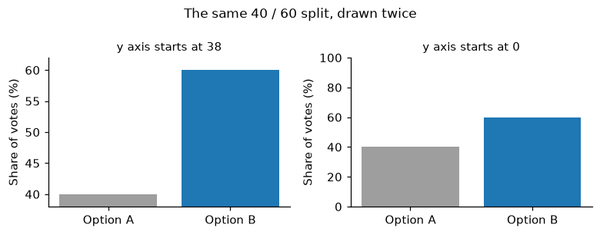

* **Neglecting annotations.** Axis labels with units, a title that says what to see, a legend when there are several series.

### Colour and accessibility

* **Choose the colour map for the data.** *Sequential* (light → dark) for one quantity from low to high (`viridis`, `YlGnBu`); *diverging* for values above and below a meaningful middle, such as 0 (`RdBu`); *qualitative* for categories with no order (`tab10`).
* About 1 in 12 men and 1 in 200 women have a colour-vision deficiency. Avoid red–green pairs, and never use colour as the **only** cue: add labels, markers or line styles.

**Discuss:** why not use a rainbow colour map (such as `jet`) for a world map of CO₂ per person?

<details><summary>Answer</summary>

A rainbow has no natural order from light to dark, so readers can't tell at a glance whether yellow is more or less than cyan. Its bright bands (yellow, cyan) create sharp edges where the data change smoothly, it is hard to read for red–green colour-blind readers, and it turns to mush in greyscale. A sequential map from light to dark reads as low → high without a legend lookup.

</details>

### The data: CO₂ emissions

The Our World in Data table you used in Week 6: one row per country (or group of countries) and year. `co2` is in million tonnes, `co2_per_capita` in tonnes per person.

In [ ]:
co2 = pd.read_csv(get_data("owid_co2_cleaned.csv"))
germany = co2[co2["country"] == "Germany"]
germany[["year", "co2", "co2_per_capita", "population"]].tail(3)

### Figures and axes

Every Matplotlib chart lives in a **figure**, the outer frame. Inside it are one or more **axes**: the areas where data is drawn. `fig, ax = plt.subplots()` creates both and gives you a name for each axes, so you decide where each series goes. You've already met an `ax` in Week 6, when you drew points on top of districts with `ax=ax`.

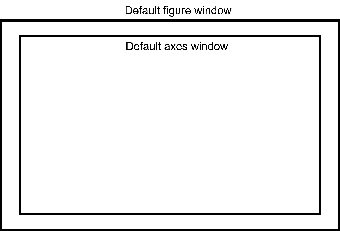

On an axes you draw with `ax.plot(x, y)` and label with `ax.set_title`, `ax.set_xlabel`, `ax.set_ylabel`. `plt.subplots(2, 1)` gives two axes, one above the other: `ax[0]` and `ax[1]`.

**Predict:** we'll draw Germany's **total** CO₂ and its CO₂ **per person** since 1950, one above the other. Will the two lines have the same shape?

In [ ]:
# ✍️ Type along: Germany's total CO₂ since 1950, then a second panel per person
recent = germany[germany["year"] >= 1950]

<details><summary>Code from class</summary>

```python
recent = germany[germany["year"] >= 1950]

fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax[0].plot(recent["year"], recent["co2"], color="tab:blue")
ax[0].set_ylabel("CO₂ (million tonnes)")
ax[0].set_title("Germany: CO₂ emissions peaked in 1979 and have almost halved since")
ax[1].plot(recent["year"], recent["co2_per_capita"], color="tab:green")
ax[1].set_ylabel("CO₂ per person (tonnes)")
ax[1].set_xlabel("Year")
plt.show()
```

</details>

Almost the same shape: both peak in **1979**. Germany's population grew by about a fifth over the period, so dividing by it changes the shape only a little. For a country whose population roughly quadrupled, such as India, total and per-person lines tell very different stories. `sharex=True` lets you read straight down from one panel to the same year in the other.

### seaborn: one call per statistical plot

**seaborn** (`import seaborn as sns`) is built on Matplotlib and designed for DataFrames: you name the table and its columns, and seaborn does the grouping, colouring and legend.

| Matplotlib | seaborn |
|---|---|
| you draw every element yourself | one call per statistical plot |
| one series per `plot` call | many series at once: `hue="country"` |
| full control | smart defaults; returns an `ax`, so you can still fine-tune it |

seaborn wants **one row per observation**, which is exactly how the CO₂ table is stored. `isin` keeps the rows whose value is in a list: a shorter way to write several `==` tests joined by `|`.

**Before we run this:** five countries, every year from 1990 to 2023. How many rows will `subset` have?

In [ ]:
five = ["China", "Germany", "India", "United Kingdom", "United States"]
subset = co2[co2["country"].isin(five) & (co2["year"] >= 1990)]
subset.shape

5 countries × 34 years = **170 rows**, one per country and year.

In [ ]:
# ✍️ Type along: CO₂ per person since 1990, one line per country

<details><summary>Code from class</summary>

```python
ax = sns.lineplot(data=subset, x="year", y="co2_per_capita", hue="country")
ax.set_xlabel("Year")
ax.set_ylabel("CO₂ per person (tonnes)")
ax.set_title("China now emits more CO₂ per person than the UK or Germany")
plt.show()
```

</details>

One call, five lines, a legend: seaborn grouped the rows by `country`. China passed the UK in **2014** and Germany in **2023**; the UK has more than halved since 1990.

**Discuss:** China emits about **12,000** million tonnes a year, the United States about **4,900**. Which chart would you show to argue "China is the biggest emitter", and which to argue "the average American emits the most"? Can both be true?

<details><summary>Answer</summary>

Both are true. A chart of **total** `co2` supports the first claim; a chart of `co2_per_capita` supports the second (US about 14 t per person, China about 8). Choosing the variable is choosing the message: say which one you plot, and why.

</details>

### Distributions: one variable, many countries

The table also has rows for **groups** of countries (World, continents, income groups). In this table only countries have a GDP value, so keeping the rows with a GDP, minus `"World"`, keeps the countries.

**Before we run this:** in 2022 the world emitted **4.6 t** of CO₂ per person on average. Do most countries emit **more** or **less** than that?

In [ ]:
countries_2022 = co2[(co2["year"] == 2022) & co2["gdp"].notna() & (co2["country"] != "World")]
print(len(countries_2022), "countries")
ax = sns.histplot(data=countries_2022, x="co2_per_capita", bins=30)
ax.set_xlabel("CO₂ per person in 2022 (tonnes)")
ax.set_ylabel("Number of countries")
plt.show()

**Less.** The distribution is **right-skewed**: most of the 164 countries sit below 5 t, with a long tail up to Qatar (37 t). The median country emits 2.7 t, and about 70 % of countries are below the world average: a few populous, high-emitting countries pull the average up (mean versus median, Week 5). A histogram shows this shape; a single average hides it.

### Comparing distributions: boxplots

A **boxplot** summarises a distribution in five numbers, so you can put several side by side:

* the line in the box is the **median** ($Q_2$); the box runs from the **lower quartile** $Q_1$ (25 %) to the **upper quartile** $Q_3$ (75 %): the middle half of the data, the **interquartile range** $IQR = Q_3 - Q_1$;
* values beyond $1.5 \times IQR$ from the box are drawn as **outliers**; the whiskers reach the most extreme values inside those limits.

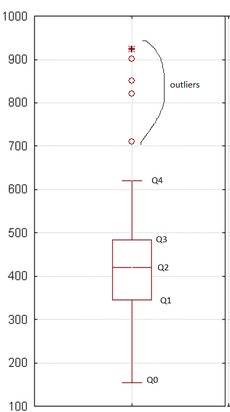

**Your turn:** has the typical country's CO₂ per person changed between 1990 and 2022? `both_years` holds the countries in those two years. Draw **one box per year** with `sns.boxplot` (`x="year"`, `y="co2_per_capita"`), label the *y* axis with its unit, and give the chart a title that states what you see.

In [ ]:
both_years = co2[co2["year"].isin([1990, 2022]) & co2["gdp"].notna() & (co2["country"] != "World")]
# your code here

<details><summary>Answer</summary>

```python
ax = sns.boxplot(data=both_years, x="year", y="co2_per_capita")
ax.set_ylabel("CO₂ per person (tonnes)")
ax.set_title("The typical country emits about the same as in 1990; the top quarter emits less")
plt.show()
```

The **median** barely moved (2.5 → 2.7 t), the **upper quartile** fell (7.5 → 6.0 t) and the lower quartile rose (0.4 → 0.9 t): countries have become a little more alike. The outliers (oil and gas producers such as Qatar) are still far above the rest. seaborn treats the numeric `year` as two categories here because it is on the *x* axis of a boxplot.

</details>

### Takeaways: charts that answer a question

* Start from the question: change over time → **line**; one distribution → **histogram**; compare distributions → **boxplot**.
* `fig, ax = plt.subplots(rows, cols)` gives you each panel; label every axis with its unit and give the chart a title that states the finding.
* seaborn draws from a DataFrame with `data=`, `x=`, `y=` and `hue=`, and returns an `ax` you can fine-tune.
* Choose the variable and the colour map for the message: total or per person; sequential, diverging or qualitative; never colour alone.

## Hour 2 · From static to interactive maps

### Last week's map, and its question

In the Week 6 guided lab you counted renewable energy projects per local authority district, and **Highland** came top with 413. The last question was: *is a count a fair way to compare districts?* The cell below rebuilds that result with last week's steps: points from a table, a spatial join, `value_counts`, `merge`.

In [ ]:
repd = pd.read_csv(get_data("repd_cleaned.csv"))
projects = gpd.GeoDataFrame(repd, geometry=gpd.points_from_xy(repd["lon"], repd["lat"]), crs="EPSG:4326")
lad = gpd.read_file(get_data("lad_dec2024_uk_buc.geojson"))

joined = gpd.sjoin(projects, lad, how="left", predicate="within")
counts = joined["LAD24NM"].value_counts().reset_index()
lad = lad.merge(counts, on="LAD24NM", how="left")
lad["count"] = lad["count"].fillna(0)
lad.sort_values("count", ascending=False)[["LAD24NM", "count"]].head(3)

### Counts or rates? Normalise before you colour

A raw **count** per area grows with the size of the area: Highland covers about 26,000 km², hundreds of times a London borough. To compare areas fairly, divide by what the count depends on: projects **per km²** (land), per person (people), or use capacity in MW instead of a count (size of the projects).

To divide by area we need areas, and areas need the right **CRS**.

**Predict:** `lad` is in `EPSG:4326`. What unit will Cardiff's `.area` be in?

In [ ]:
lad[lad["LAD24NM"] == "Cardiff"].area

About 0.018 **square degrees**, plus a warning from GeoPandas. A square degree has no fixed size: a degree of longitude shrinks from about 111 km at the equator to about 69 km in Cardiff. Areas, like distances and buffers, are measured in a **projected** CRS in metres: `EPSG:27700` for Great Britain.

In [ ]:
# ✍️ Type along: area in km² (EPSG:27700), then projects per 100 km²

<details><summary>Code from class</summary>

```python
lad["area_km2"] = lad.to_crs(epsg=27700).area / 1e6       # m² → km²
lad["per_100km2"] = 100 * lad["count"] / lad["area_km2"]
lad.sort_values("per_100km2", ascending=False)[["LAD24NM", "count", "area_km2", "per_100km2"]].head()
```

</details>

`to_crs` is used only to **measure**; `lad` itself stays in longitude/latitude, which is what web maps need later. The top of the list is a surprise: the **City of London**, with 3 projects on 2.7 km², has 112 projects per 100 km². A rate built on very small numbers is unstable: one more project would change it by a third.

### Two maps of the same data

**Before we run this:** Highland is the darkest district on the count map. Where will it be on the density map?

In [ ]:
lad["area_km2"] = lad.to_crs(epsg=27700).area / 1e6
lad["per_100km2"] = 100 * lad["count"] / lad["area_km2"]

fig, ax = plt.subplots(1, 2, figsize=(11, 7))
lad.plot(column="count", cmap="YlGnBu", legend=True, ax=ax[0], legend_kwds={"shrink": 0.5})
lad.plot(column="per_100km2", cmap="YlGnBu", legend=True, ax=ax[1], legend_kwds={"shrink": 0.5})
ax[0].set_title("Projects per district (count)")
ax[1].set_title("Projects per 100 km² (density)")
for a in ax:
    a.set_axis_off()
plt.show()

Highland drops from **1st** to about **350th** of 361: lots of projects, but spread over a huge area. The density map has its own problem: it is **almost entirely pale**, because a few tiny urban districts take the whole dark end of a continuous colour scale. The data is skewed, like the CO₂ histogram.

### Classes and colour maps

* A **continuous** scale gives every value its own shade; one extreme value squeezes everything else into a few pale shades.
* **Classes** group the values: equal intervals (same width) or **quantiles** (the same number of districts in each class). Quantile classes show the ranking even when the data is skewed.
* The colour map follows the data: **sequential** for low → high, **diverging** around a meaningful middle, **qualitative** for categories.

**Quick check:** which kind of colour map for (a) projects per 100 km², (b) the technology of each project, (c) the change in the number of projects since last year, which can be negative?

<details><summary>Answer</summary>

(a) **sequential** (one quantity, low → high); (b) **qualitative** (categories with no order); (c) **diverging**, centred on 0 (fewer and more projects in two different colours).

</details>

### Static or interactive?

| Static (GeoPandas `.plot()`) | Interactive (Folium) |
|---|---|
| reports, papers, printed figures | exploring: zoom, pan, hover, click |
| full control of layout, legend, classes | layers you switch on and off |
| the Matplotlib figure and axes you know | shared as a web page (`.html`) |

**Folium** is a Python wrapper around **Leaflet**, a JavaScript library for web maps. You give it latitude and longitude; it draws the map in **Web Mercator** (`EPSG:3857`), the projection of web map tiles. Web Mercator enlarges areas far from the equator (Scotland looks bigger than it is), so compare areas with numbers, not by eye. Our basemap tiles come from **OpenStreetMap**, which asks you to keep its attribution visible in the map corner.

In [ ]:
# ✍️ Type along: a map of Cardiff with one marker (a popup and a tooltip)

<details><summary>Code from class</summary>

```python
m = folium.Map(location=[51.4816, -3.1791], zoom_start=12, tiles="OpenStreetMap")   # [latitude, longitude]
folium.Marker([51.4816, -3.1791], popup="Cardiff city centre", tooltip="Hover or click me").add_to(m)
m
```

</details>

Folium wants **[latitude, longitude]**: the opposite order of `points_from_xy(lon, lat)`. Swap them and Cardiff lands in the Indian Ocean. A cell that ends with the map's name (`m`) displays it. Hover over the marker to see the **tooltip**; click it to open the **popup**, which can hold longer text.

### Points from a table: circle markers and layers

Cardiff's projects are the rows of `joined` whose district is Cardiff:

In [ ]:
cardiff = joined[joined["LAD24NM"] == "Cardiff"]
print(len(cardiff), "projects")
cardiff["status"].value_counts().head(3)

A `CircleMarker` is a circle with a radius in **screen pixels**, so it stays readable at every zoom. To draw one per project we loop over the rows: `for _, row in cardiff.iterrows():` gives one row at a time (`_` is the index, which we don't need), and `row["lat"]` reads a value. A **`FeatureGroup`** collects markers into a layer, and **`LayerControl`** adds the switch in the corner.

In [ ]:
# ✍️ Type along: one CircleMarker per Cardiff project, in two layers you can switch
m = folium.Map(location=[51.49, -3.18], zoom_start=11, tiles="OpenStreetMap")
built = folium.FeatureGroup(name="Operational").add_to(m)
not_built = folium.FeatureGroup(name="Not (yet) operational").add_to(m)

<details><summary>Code from class</summary>

```python
m = folium.Map(location=[51.49, -3.18], zoom_start=11, tiles="OpenStreetMap")
built = folium.FeatureGroup(name="Operational").add_to(m)
not_built = folium.FeatureGroup(name="Not (yet) operational").add_to(m)

for _, row in cardiff[cardiff["status"] == "Operational"].iterrows():
    folium.CircleMarker([row["lat"], row["lon"]], radius=6, color="green", fill=True,
                        tooltip=row["project_name"]).add_to(built)
for _, row in cardiff[cardiff["status"] != "Operational"].iterrows():
    folium.CircleMarker([row["lat"], row["lon"]], radius=6, color="orange", fill=True,
                        tooltip=row["project_name"]).add_to(not_built)

folium.LayerControl().add_to(m)
m
```

</details>

Markers go into a **layer** (`.add_to(built)`), and the layer is already on the map. Switch the layers in the top-right corner. Only 8 of Cardiff's 29 projects are operational; most of the others are small rooftop solar and battery schemes still awaiting construction.

**Your turn:** make a map of Cardiff's **solar** projects only (`technology` is `"Solar Photovoltaics"`), as orange circle markers, with a **tooltip** that shows the project name and its capacity in MW, e.g. `"Lamby Way Solar Farm: 8.9 MW"`.

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
solar = cardiff[cardiff["technology"] == "Solar Photovoltaics"]
m_solar = folium.Map(location=[51.49, -3.18], zoom_start=11, tiles="OpenStreetMap")
for _, row in solar.iterrows():
    folium.CircleMarker([row["lat"], row["lon"]], radius=6, color="orange", fill=True,
                        tooltip=f"{row['project_name']}: {row['capacity_mw']} MW").add_to(m_solar)
m_solar
```

Filtering first and then looping is the pattern for any subset: one technology, one status, one district.

</details>

**Discuss:** someone wants all 12,953 UK projects on one Folium map. Is that a good idea? Popups or tooltips?

<details><summary>Answer</summary>

Every marker is written into the web page, so 13,000 of them make the map slow (Folium works best with fewer than about 10,000 shapes), and at national zoom they overlap into a blob where hovering is useless. Better: **filter** (one region, one technology), **sample**, or **aggregate** to districts and draw a choropleth, as below. For the markers that remain, a tooltip is fine for a name; use a popup for longer details.

</details>

### An interactive choropleth

`folium.Choropleth` colours polygons from a table: `columns` names the key and the value, and `key_on` says where the same key sits in each polygon's properties. `bins` sets the class limits; here the 0 %, 20 %, …, 100 % **quantiles**, so each colour holds a fifth of the districts. A transparent `GeoJson` layer on top adds the hover tooltip.

**Predict:** with quantile classes, how many districts fall in each of the five colours, and will Highland still look pale?

In [ ]:
m = folium.Map(location=[54.5, -3], zoom_start=5, tiles="OpenStreetMap")
folium.Choropleth(
    geo_data=lad, data=lad, columns=["LAD24NM", "per_100km2"], key_on="feature.properties.LAD24NM",
    bins=list(lad["per_100km2"].quantile([0, 0.2, 0.4, 0.6, 0.8, 1])),
    fill_color="YlGnBu", fill_opacity=0.7, line_opacity=0.2,
    legend_name="Renewable energy projects per 100 km² (quantile classes)",
).add_to(m)
folium.GeoJson(lad, style_function=lambda feature: {"fillOpacity": 0, "weight": 0},
               tooltip=folium.GeoJsonTooltip(["LAD24NM", "count", "per_100km2"])).add_to(m)
m

About **72 districts per colour** (361 / 5). The pattern now shows: the darkest fifth is almost entirely **urban** districts (London boroughs, Birmingham, Manchester, Liverpool, Bristol, Glasgow, and Cardiff and Newport in Wales), with many small rooftop and battery projects packed into a small area; Highland stays in the palest fifth. Hover over a district to read its numbers. Neither map is "the truth": a count answers *where are most projects?*, a density answers *where are projects packed most tightly?* Choose the denominator for the question, and say which one you used.

### Takeaways: from static to interactive maps

* Normalise before you colour: counts favour big areas. Measure areas in a projected CRS (`to_crs(epsg=27700)`), never in degrees, and beware rates built on tiny numbers.
* Skewed data: quantile **classes** show the ranking; pick a sequential, diverging or qualitative colour map to match the data.
* Folium: `folium.Map(location=[lat, lon])` → `Marker` / `CircleMarker` (tooltip on hover, popup on click) → `FeatureGroup` + `LayerControl` → `Choropleth`. A cell ending in `m` shows the map.
* Too many points? Filter, sample or aggregate.

## Hour 3 · Satellite rasters with Google Earth Engine

### From Week 6 rasters to real satellite images

In Week 6 a raster was a grid of 48 pixel values with a CRS, a resolution and an extent, one grid per **band**. The EU's Copernicus **Sentinel-2** satellites photograph every piece of land every few days in 13 bands at 10–60 m resolution. Its surface-reflectance values are stored as **reflectance × 10,000**, as whole numbers: a red value of 3,000 means that the surface reflects 30 % of the red light. Healthy leaves reflect only a few per cent of red light but 30–50 % of near-infrared light.

### What Earth Engine adds

One Sentinel-2 tile has about 120 million pixels per band, and the archive goes back to 2015: far too much to download. **Google Earth Engine** keeps a catalogue of public datasets (Sentinel, Landsat, land cover, elevation, climate, …) **and** computers next to the data. Your Python code only writes a **recipe**; the servers do the work and send back small results.

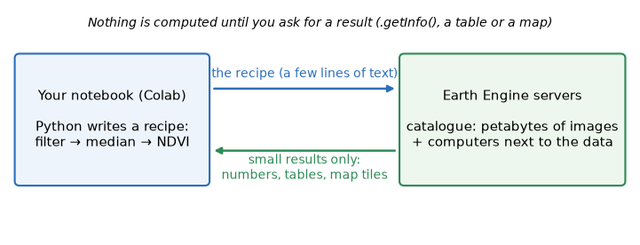

| Earth Engine | You know it as |
|---|---|
| `ee.Image` | a multi-band raster (Week 6) |
| `ee.ImageCollection` | a stack of images, e.g. every Sentinel-2 image of Cardiff in one summer |
| `ee.Geometry`, `ee.FeatureCollection` | points and polygons; a FeatureCollection is like a GeoDataFrame |

**Quick check:** we ask for the median of 22 Sentinel-2 images of Cardiff. Where is the median computed, and what reaches Colab?
1. Colab downloads the 22 images and computes the median.
2. Google's servers compute it; only a number, a small table or map tiles come back.

<details><summary>Answer</summary>

**2.** And nothing at all is computed until you ask for a result: printing a value with `.getInfo()`, fetching a table, or drawing a map.

</details>

### Choosing a collection

Every dataset has an **ID** in the Earth Engine catalogue (<https://developers.google.com/earth-engine/datasets>). Check its catalogue page before you use it: datasets get replaced, and deprecated ones carry a warning.

| ID | What it is | Use it? |
|---|---|---|
| `COPERNICUS/S2_SR` | Sentinel-2 surface reflectance | no: **deprecated**, replaced by the next line |
| `COPERNICUS/S2_SR_HARMONIZED` | the same product, with values on one consistent scale across processing versions | **yes**: today's collection |
| `LANDSAT/LC09/C02/T1_L2` | Landsat 9 surface reflectance, 30 m | an alternative: coarser pixels, and a longer archive with earlier Landsats |

### Two ways to follow this hour

* **With Earth Engine:** you need a Google Cloud project registered for noncommercial Earth Engine use (see the module's set-up instructions). Type its **ID** into `EE_PROJECT` (in Colab, the form field to the right of the cell), run the cell, and allow access in the Google sign-in pop-up.
* **Without Earth Engine (yet):** leave `EE_PROJECT` empty and run the cell anyway. Follow the live code on the screen. Under each Earth Engine step you'll find the result of the same code from a run in October 2026, so you can answer every question. The *Your turn* in this hour works for everyone.

Use only your own project ID: every request, and its quota, runs in the project you name. Problems? See *Earth Engine troubleshooting* at the end of this notebook.

In [ ]:
import ee

EE_PROJECT = ""  #@param {type:"string"}
EE_PROJECT = EE_PROJECT or os.environ.get("EE_PROJECT", "")     # form field, else environment variable
EE_READY = False

if EE_PROJECT:
    ee.Authenticate()                     # Colab: a Google sign-in pop-up
    ee.Initialize(project=EE_PROJECT)
    EE_READY = True
    print("Earth Engine ready | ee", ee.__version__)
else:
    print("No project ID: follow the demonstration. The results from class are shown under each Earth Engine step.")

### A collection of images: where, when, how cloudy

We filter the collection by **where** (`filterBounds`: a box around Cardiff), **when** (`filterDate`: summer 2025) and **how cloudy** (a metadata property of every image). `ee.Geometry.BBox(west, south, east, north)` takes longitude first, like `points_from_xy`.

In [ ]:
# ✍️ Type along (Earth Engine): Sentinel-2 over Cardiff, summer 2025, less than 20 % cloud

<details><summary>Code from class</summary>

```python
aoi = ee.Geometry.BBox(-3.35, 51.40, -3.05, 51.56)      # west, south, east, north: Cardiff and the coast

s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
      .filterBounds(aoi)
      .filterDate("2025-05-01", "2025-08-31")
      .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20)))

print("images found:", s2.size().getInfo())
first = s2.first()
print("first image taken on:", ee.Date(first.get("system:time_start")).format("YYYY-MM-dd").getInfo())
```

</details>

**Result from a run in October 2026:**
```
images found: 22
first image taken on: 2025-05-02
```
`s2` is a recipe, not 22 downloaded images. `.getInfo()` is the moment Earth Engine computes and sends a result back; use it sparingly, on small results.

### Bands, pixel values and one cloud-free image

`B2`, `B3`, `B4` are blue, green and red, and `B8` is near-infrared (NIR), all at 10 m; `B11` and `B12` are short-wave infrared at 20 m. The other bands hold quality and cloud information.

One image may be cloudy in places. A **median composite** takes, for every pixel and band, the median over all 22 images: clouds are bright outliers, so they drop out. Then we read the red and NIR values under three points. The `10` is the **scale**: the pixel size, in metres, at which Earth Engine reads the image.

**Before we run this:** a park, a shopping street and the water of Cardiff Bay. At which place will NIR be much larger than red?

In [ ]:
# ✍️ Type along (Earth Engine): a median composite, then red and NIR at three places

<details><summary>Code from class</summary>

```python
image = s2.median()

places = {
    "Pontcanna Fields (park)":    [-3.1990, 51.4900],
    "Queen Street (city centre)": [-3.1745, 51.4818],
    "Cardiff Bay (water)":        [-3.1640, 51.4560],
}
for name, lon_lat in places.items():
    point = ee.Geometry.Point(lon_lat)
    values = image.select(["B4", "B8"]).reduceRegion(ee.Reducer.first(), point, 10).getInfo()
    print(f"{name:28s} red B4 = {values['B4']:7.1f}   NIR B8 = {values['B8']:7.1f}")
```

</details>

**Result from a run in October 2026:**

| Place | red (B4) | NIR (B8) |
|---|---|---|
| Pontcanna Fields (park) | 644 | 3,148 |
| Queen Street (city centre) | 1,829 | 1,968 |
| Cardiff Bay (water) | 174.5 | 107 |

In the park NIR is about **five times** red: leaves absorb red light and reflect NIR. The street reflects both about equally; water absorbs almost all NIR. This is vector meets raster: a **point** reads the pixel under it, as with the river gauge in Week 6.

### From pixel values to colours: visualisation parameters

A screen mixes three colours: red, green and blue. **Visualisation parameters** say which bands go to which colour and how to stretch their values:
* `bands`: three bands for a colour image, or one band plus a `palette`;
* `min`, `max`: values at or below `min` are drawn dark, values at or above `max` at full brightness.

**True colour** (`B4, B3, B2`) looks like a photo. **False colour** (`B8, B4, B3`) puts NIR into the red channel, so vegetation turns bright red.

**Predict:** with `"min": 0, "max": 3000`, how will a bright roof with red 3,500, green 3,400 and blue 3,300 look in true colour?

<details><summary>Answer</summary>

**Pure white**: all three values are above `max`, so all three channels are at full brightness. Detail above `max` is lost (it *saturates*). A larger `max` shows bright surfaces better but makes everything else darker.

</details>

Earth Engine can act as a **tile server**, like OpenStreetMap in Hour 2: `getMapId()` asks it to draw our image with our visualisation parameters, and `folium.TileLayer` puts those tiles on the map as a layer. This helper is the whole connection:

In [ ]:
def add_ee_layer(folium_map, ee_image, vis_params, name):
    """Add an Earth Engine image to a Folium map as a tile layer."""
    map_id = ee_image.getMapId(vis_params)                  # Earth Engine draws the tiles on its servers
    folium.TileLayer(
        tiles=map_id["tile_fetcher"].url_format,            # a tile URL, like OpenStreetMap's
        attr="Google Earth Engine; contains modified Copernicus Sentinel data 2025",
        name=name, overlay=True, control=True,
    ).add_to(folium_map)

In [ ]:
# ✍️ Type along (Earth Engine): true and false colour as two switchable layers on a Folium map

<details><summary>Code from class</summary>

```python
true_colour = {"bands": ["B4", "B3", "B2"], "min": 0, "max": 3000}
false_colour = {"bands": ["B8", "B4", "B3"], "min": 0, "max": 4000}

m = folium.Map(location=[51.48, -3.18], zoom_start=12, tiles="OpenStreetMap")
add_ee_layer(m, image, true_colour, "True colour (B4, B3, B2)")
add_ee_layer(m, image, false_colour, "False colour (B8, B4, B3)")
folium.LayerControl().add_to(m)
m
```

</details>

**Result from a run in October 2026** (false-colour layer switched on):

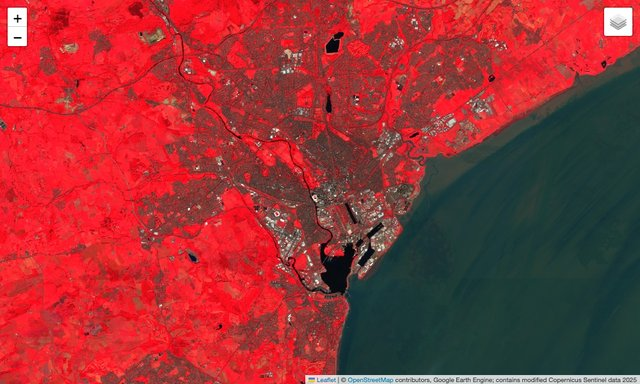

*Sentinel-2 median composite, May–August 2025. Contains modified Copernicus Sentinel data 2025, processed in Google Earth Engine; basemap © OpenStreetMap contributors.*

Parks, fields and gardens glow red; streets and roofs are grey-blue; water is almost black. Zoom in until you see single **10 m pixels**: the Week 6 grid at real scale. Earth Engine draws only the tiles you look at.

### A derived raster: NDVI

Band maths on the server, pixel by pixel, exactly as in Week 6:

$$\mathrm{NDVI} = \frac{\mathrm{NIR} - \mathrm{Red}}{\mathrm{NIR} + \mathrm{Red}} = \frac{B8 - B4}{B8 + B4}$$

`normalizedDifference(["B8", "B4"])` computes it for every pixel. NDVI is a **single band**, so it is drawn with a **palette**: a list of colours from `min` to `max`.

In [ ]:
# ✍️ Type along (Earth Engine): NDVI on the server, shown over the true-colour layer

<details><summary>Code from class</summary>

```python
ndvi = image.normalizedDifference(["B8", "B4"]).rename("NDVI")
# palette from min to max: water (blue), built-up (red), sparse (yellow), vegetation (green)
ndvi_vis = {"min": -0.3, "max": 0.8, "palette": ["#2166ac", "#d73027", "#fee08b", "#1a9850"]}

m_ndvi = folium.Map(location=[51.48, -3.18], zoom_start=12, tiles="OpenStreetMap")
add_ee_layer(m_ndvi, image, true_colour, "True colour")
add_ee_layer(m_ndvi, ndvi, ndvi_vis, "NDVI")
folium.LayerControl().add_to(m_ndvi)
m_ndvi
```

</details>

**Result from a run in October 2026:**

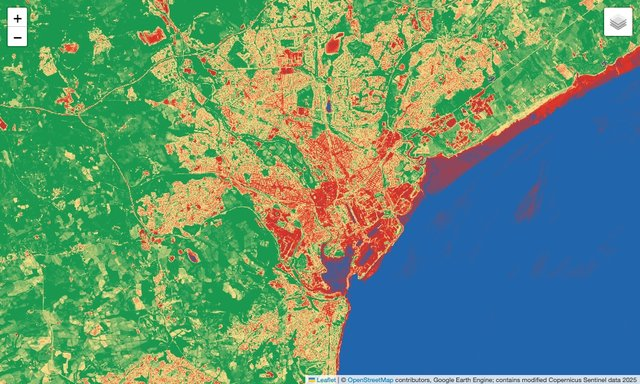

*Sentinel-2 median composite, May–August 2025. Contains modified Copernicus Sentinel data 2025, processed in Google Earth Engine; basemap © OpenStreetMap contributors.*

**Your turn** (no Earth Engine needed): the server's NDVI at the three places was **0.66** (park), **0.04** (street) and **−0.24** (bay). Check it: use the red and NIR values from the table above and compute NDVI for each place in Python.

In [ ]:
red = {"park": 644, "street": 1829, "bay": 174.5}
nir = {"park": 3148, "street": 1968, "bay": 107}
# your code here

<details><summary>Answer</summary>

```python
for place in red:
    ndvi_value = (nir[place] - red[place]) / (nir[place] + red[place])
    print(f"{place:7s} NDVI = {ndvi_value:5.2f}")
```

```
park    NDVI =  0.66
street  NDVI =  0.04
bay     NDVI = -0.24
```
The same numbers: Earth Engine runs the same formula, on millions of pixels instead of three.

</details>

Water is negative, as in Week 6: it absorbs near-infrared light almost completely, so NIR < Red.

### Raster meets vector: NDVI per district

A **point** reads one pixel; a **polygon** summarises all the pixels inside it, as with the park in Week 6. A GeoDataFrame becomes an Earth Engine `FeatureCollection` through its GeoJSON form (`__geo_interface__`), and `reduceRegions` computes one summary per polygon, on the server. The cell below works both ways: with Earth Engine it computes the means; without it, it shows the result of the same code from October 2026.

**Predict:** which of these five South Wales districts has the **lowest** mean NDVI in summer: Cardiff, Caerphilly, Newport, Rhondda Cynon Taf or the Vale of Glamorgan?

In [ ]:
five_lads = ["Cardiff", "Vale of Glamorgan", "Rhondda Cynon Taf", "Caerphilly", "Newport"]
south_wales = lad[lad["LAD24NM"].isin(five_lads)][["LAD24NM", "geometry"]]

if EE_READY:
    lad_ee = ee.FeatureCollection(south_wales.__geo_interface__)      # GeoDataFrame -> Earth Engine polygons
    summer = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
              .filterBounds(lad_ee.geometry())
              .filterDate("2025-05-01", "2025-08-31")
              .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
              .median())
    stats = summer.normalizedDifference(["B8", "B4"]).reduceRegions(
        collection=lad_ee, reducer=ee.Reducer.mean(), scale=20)
    table = ee.data.computeFeatures({"expression": stats, "fileFormat": "PANDAS_DATAFRAME"})
    ndvi_by_lad = table[["LAD24NM", "mean"]]
else:   # the result of the code above, from a run in October 2026
    ndvi_by_lad = pd.DataFrame({
        "LAD24NM": ["Rhondda Cynon Taf", "Caerphilly", "Vale of Glamorgan", "Newport", "Cardiff"],
        "mean": [0.723, 0.718, 0.671, 0.615, 0.557]})
ndvi_by_lad.sort_values("mean", ascending=False).round(2)

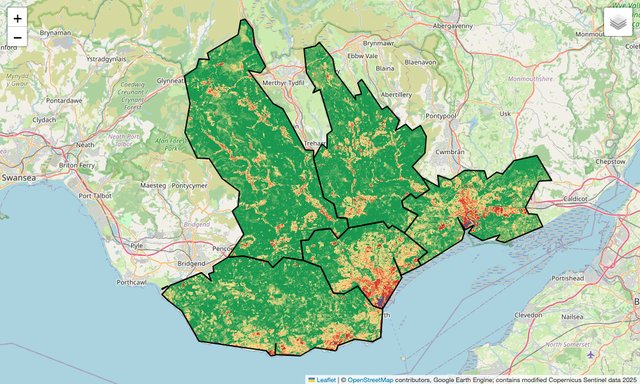

*Local Authority District boundaries (December 2024), Office for National Statistics, Open Government Licence v3.0.* *Sentinel-2 median composite, May–August 2025. Contains modified Copernicus Sentinel data 2025, processed in Google Earth Engine; basemap © OpenStreetMap contributors.*

**Cardiff** is lowest (0.56): city centre, docks and roads. The valleys of Rhondda Cynon Taf and Caerphilly, with moorland and forest, are highest. `scale=20` computes the mean on 20 m pixels to keep the request fast.

**Discuss:** Pontcanna Fields, inside Cardiff, has an NDVI of 0.66, yet Cardiff's mean is 0.56. What does one mean per district hide? Where have you met this problem today already?

<details><summary>Answer</summary>

The mean mixes everything inside the boundary: parks near 0.7, streets near 0, the bay below 0. Two districts with the same mean can look completely different inside. It is the same lesson as counts and densities in Hour 2: one number per polygon is a **choice of summary**, and a map of that number shows only what the summary keeps.

</details>

### Where this leads: pixels as a table

Machine learning needs a **table**: one row per example, one column per feature. Sampling a raster gives exactly that: each sampled **pixel** becomes a row, each **band** (and NDVI) a column. Add a label, such as the land cover of each pixel, and a model can learn from it: that is Weeks 11–12.

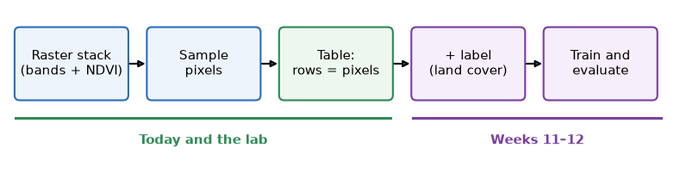

In the guided lab you'll open such a table: 4,800 Sentinel-2 pixels around Cardiff, sampled with Earth Engine and saved as a file, so it works for everyone.

### Takeaways: satellite rasters with Earth Engine

* Earth Engine keeps the catalogue **and** the computation on Google's servers; Python sends a recipe and gets small results back (`.getInfo()`, tables, map tiles).
* Pick a current collection ID (`COPERNICUS/S2_SR_HARMONIZED`, not the deprecated `S2_SR`), filter it by place, date and cloud, and reduce it to one image with `.median()`.
* Visualisation parameters choose the bands and the stretch (`min`, `max`), or a `palette` for one band; `add_ee_layer` puts the result on a Folium map.
* NDVI is `normalizedDifference(["B8", "B4"])`: the Week 6 formula, on millions of pixels.
* Raster meets vector: a point reads a pixel; a polygon summarises the pixels inside it (`reduceRegions`).

## Transition to the guided lab

**You now know** how to choose and build a chart with Matplotlib and seaborn, make a fair choropleth and an interactive Folium map with layers, and show Earth Engine rasters on a Folium map.

**The guided lab** (`W07b_guided_lab_student.ipynb`, one hour) asks: *where are Wales's wind and solar farms, and what does a satellite tell us about the land around them?* We work through five steps together, each with a checkpoint and a question:
1. keep Wales's operational wind and solar projects;
2. an interactive map with one layer per technology;
3. 4,800 satellite pixels as a table, with NDVI by band maths;
4. a seaborn boxplot: does NDVI tell vegetation, urban land and water apart?
5. satellite NDVI and the projects on one map, with Earth Engine or with the result from class.

## Week 7 takeaways

* Choose the chart, the variable and the colour map for the question: lines for time, histograms and boxplots for distributions; total or per person; sequential, diverging or qualitative.
* Normalise before you colour, measure in a projected CRS, and use classes for skewed data.
* Folium turns GeoPandas results into maps people can explore: markers, layers, choropleths.
* Earth Engine computes on the server and returns map tiles and small tables; NDVI and per-district means are the Week 6 raster ideas at real scale.

## Where next

**Week 8 · Text Processing.** All cohorts are together again. The data becomes **text**: you'll find patterns with regular expressions and process documents with NLTK, building on the pandas `.str` methods from Week 6.

**Weeks 11–12** come back to today's pixels: a table of Sentinel-2 pixels becomes the training data for a land-cover classifier.

Before next week: rerun this notebook top to bottom and finish any *Your turn* you skipped.

## Optional: explore after class

None of this is needed later.

**A relationship: richer countries, more CO₂ per person?** A **scatter plot** shows a relationship between two variables. GDP per person spans from a few hundred to over 100,000 dollars, so a **log scale** on the *x* axis spreads the countries out.

In [ ]:
rich = countries_2022.copy()
rich["gdp_per_capita"] = rich["gdp"] / rich["population"]
ax = sns.scatterplot(data=rich, x="gdp_per_capita", y="co2_per_capita")
ax.set_xscale("log")
ax.set_xlabel("GDP per person (international $, log scale)")
ax.set_ylabel("CO₂ per person (tonnes)")
plt.show()

**Save a Folium map as a web page.** `m.save("cardiff_projects.html")` writes the map to a file (in Colab: the *Files* panel); open it in a browser or send it to someone. Earth Engine layers in a saved map stop working after some hours, because their tile URLs expire.

**Another basemap.** `tiles="OpenTopoMap"` gives a topographic style that needs no key; keep its attribution visible.

**More indices with Earth Engine.** The same `normalizedDifference` gives other indices:
* **NDWI** = (Green − NIR) / (Green + NIR) = `normalizedDifference(["B3", "B8"])`: positive over water;
* **NDBI** = (SWIR − NIR) / (SWIR + NIR) = `normalizedDifference(["B11", "B8"])`: high over roofs and roads.

Map each with a palette from blue to red and `min=-0.5, max=0.5`. Where is each one high? And for the NDVI map: what happens to the parks if you change `"max": 0.8` to `0.5` in `ndvi_vis`? (Every pixel above 0.5 gets the same green: the palette *saturates*.)

<details><summary>Code: NDWI and NDBI on one map</summary>

```python
ndwi = image.normalizedDifference(["B3", "B8"])
ndbi = image.normalizedDifference(["B11", "B8"])
blue_red = {"min": -0.5, "max": 0.5, "palette": ["#2166ac", "#f7f7f7", "#b2182b"]}

m_idx = folium.Map(location=[51.48, -3.18], zoom_start=12, tiles="OpenStreetMap")
add_ee_layer(m_idx, ndwi, blue_red, "NDWI")
add_ee_layer(m_idx, ndbi, blue_red, "NDBI")
folium.LayerControl().add_to(m_idx)
m_idx
```

</details>

### Earth Engine troubleshooting

| What you see | What to do |
|---|---|
| The setup cell prints *No project ID* | Type your Cloud project **ID** (not its name) into `EE_PROJECT` and re-run the cell |
| An error saying the project is **not registered** for Earth Engine | Register the project for noncommercial use (Earth Engine page of the Google Cloud console), then re-run |
| An error saying the **Earth Engine API is not enabled** | Enable the *Earth Engine API* for that project in the Google Cloud console, wait a minute, re-run |
| An error about **permission** | The Google account you chose in the pop-up must own the project or be a member of it. Run `ee.Authenticate(force=True)` and choose the right account |
| No sign-in pop-up appears | Allow pop-ups for colab.research.google.com, then re-run the setup cell |
| The map shows OpenStreetMap but no satellite layer | Tick the layer in the layer control and zoom in; if the map is some hours old, re-run its cell (tile URLs expire) |
| *Computation timed out* or *memory limit* | Use a smaller area, a shorter date range or a larger `scale` |
| A cell is slow | Look for `.getInfo()` inside a loop: fetch one combined result instead |

## Credits

* CO₂ data: Our World in Data, *CO₂ and Greenhouse Gas Emissions* dataset, CC BY 4.0.
* Renewable Energy Planning Database, Q2 July 2025, Department for Energy Security and Net Zero; Local Authority Districts (December 2024) Boundaries UK BUC, Office for National Statistics; contains OS data © Crown copyright and database right 2024. Both contain public sector information licensed under the Open Government Licence v3.0.
* Satellite images: contains modified Copernicus Sentinel data 2025, processed in Google Earth Engine.
* Basemap tiles: © OpenStreetMap contributors.